## Number of extracted papers by each group member

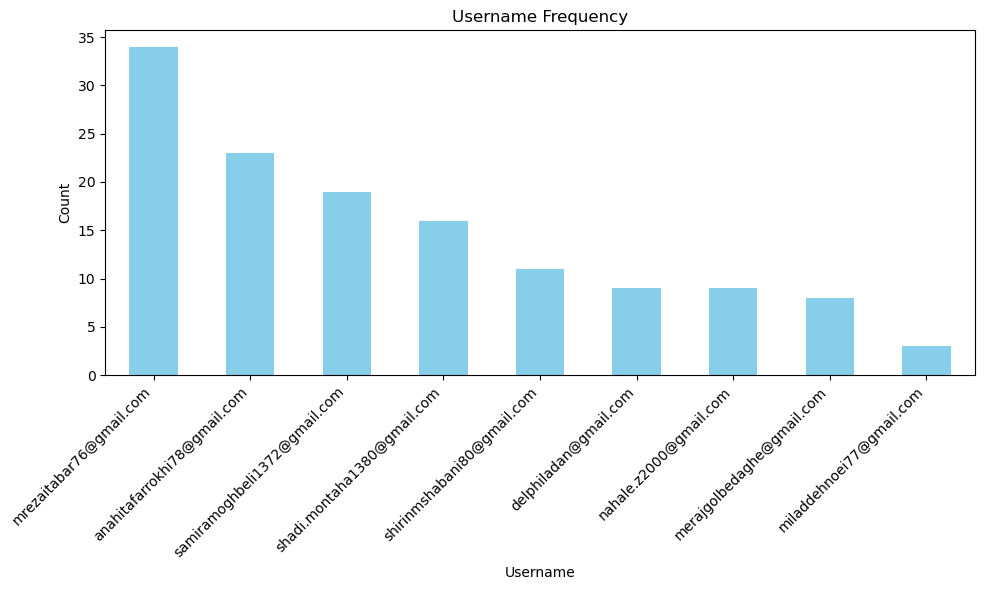

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# Load the CSV file
df = pd.read_csv('STZ.csv')  # Replace with your actual CSV filename

# Count repetitions of each username
username_counts = df['Username'].value_counts()

# Plotting the bar chart
plt.figure(figsize=(10, 6))
username_counts.plot(kind='bar', color='skyblue')
plt.title('Username Frequency')
plt.xlabel('Username')
plt.ylabel('Count')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


In [2]:
import pandas as pd

# Prevent truncating long strings
pd.set_option('display.max_colwidth', None)

# Load CSVs
group_df = pd.read_csv("Group.csv")
stz_df = pd.read_csv("STZ.csv")

# Column names
link_col = "Add plots & tables: please name each plot or table file by  each Behavioural Type and Method (Test, task, maze)"
doi_col = "Doi Paper"
N_control_col = "In control behavioral group: N = "
N_STZ_col =  "In STZ behavioral group: N = "


behrad_rows = group_df[group_df["group"] == "Behrad"]

# Adjust indices for pandas (idx counts from 1 including header row)
adjusted_indices = behrad_rows["idx"] - 2

# Extract data from STZ.csv and include original idx
result = pd.DataFrame({
    "idx": behrad_rows["idx"].values,
    "Link": stz_df.iloc[adjusted_indices][link_col].values,
    "DOI": stz_df.iloc[adjusted_indices][doi_col].values,
    "N control": stz_df.iloc[adjusted_indices][N_control_col].values,
    "N STZ" : stz_df.iloc[adjusted_indices][N_STZ_col].values
})

# Save to CSV
result.to_csv("Behrad_links.csv", index=False)

print("✅ Extracted idx, links, and DOIs saved to Behrad_links.csv")


✅ Extracted idx, links, and DOIs saved to Behrad_links.csv


Dataset contains 54 records

First few records:


,Timestamp,Username,Correspoding Email address:,Doi Paper,Title Paper,"Authors (First author {Last Name} et al., Year)",Is Paper Excluded?,"If the paper is excluded, Reason of excultion",Subject,Gender,...,In control molecular group: N = .27,In STZ molecular group: N = .27,Proteins (Graph / Data).27,Amyloid beta (Aβ) isoform (type).27,tau isoform (type).27,GSK-3β isoform (type).27,APP isoform (type).27,AchE isoform (type).26,Graphs or Charts (Immunofluorescent).6,Other molecular techniques if existed.27
0,2025/07/22 2:17:00 PM GMT+3:30,shirinmshabani80@gmail.com,fe.t@hotmail.com / rspanevello@gmail.com,https://doi.org/10.1007/s12035-021-02627-z,Investigating the Effect of Inosine on Brain P...,"Teixeira et al., 2021",No,NaN,Rats,male,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2025/07/22 6:02:51 PM GMT+3:30,delphiladan@gmail.com,Email: fatih172@gmail.com,DOI: 10.12871/00039829201913,N–(p–amylcinnamoyl) anthranilic acid attenuate...,MEHMET GÖL,No,NaN,Rats,male,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2025/07/22 8:15:02 PM GMT+3:30,samiramoghbeli1372@gmail.com,drfislam@gmail.com,10.1016/j.jns.2014.10.044,"Effect of hesperidin on neurobehavioral, neuro...","Hayate Javed et al.,2015",No,NaN,Mice,male,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2025/07/22 8:45:49 PM GMT+3:30,shirinmshabani80@gmail.com,luciellisavegnago@yahoo.com.br,https://doi.org/10.1021/acschemneuro.0c00615,"Effect of QTC-4-MeOBnE Treatment on Memory, Ne...","Fronza et al., 2021",Yes (submit form),All groups are injected with a drug (QTC-4-MeO...,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2025/07/23 10:23:05 AM GMT+3:30,delphiladan@gmail.com,elhamkheradmand25@gmail.com,https://doi.org/10.1016/j.biopha.2017.11.047,Neuroprotective effect of hesperetin and nano-...,"E. kheradmand et al., 2018",No,NaN,Rats,male,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Missing values per column:


Timestamp                                    0
Username                                     0
Correspoding Email address:                  0
Doi Paper                                    1
Title Paper                                  0
                                            ..
GSK-3β isoform (type).27                    54
APP isoform (type).27                       54
AchE isoform (type).26                      54
Graphs or Charts (Immunofluorescent).6      54
Other molecular techniques if existed.27    54
Length: 335, dtype: int64

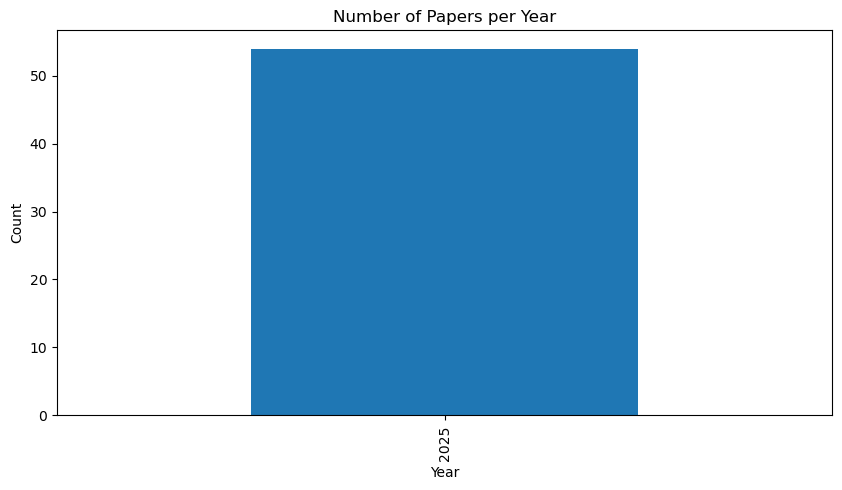

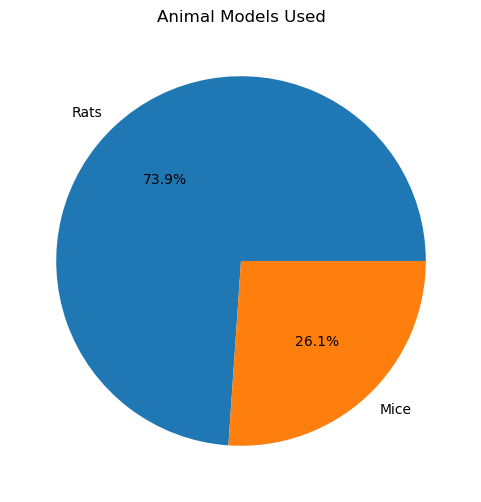

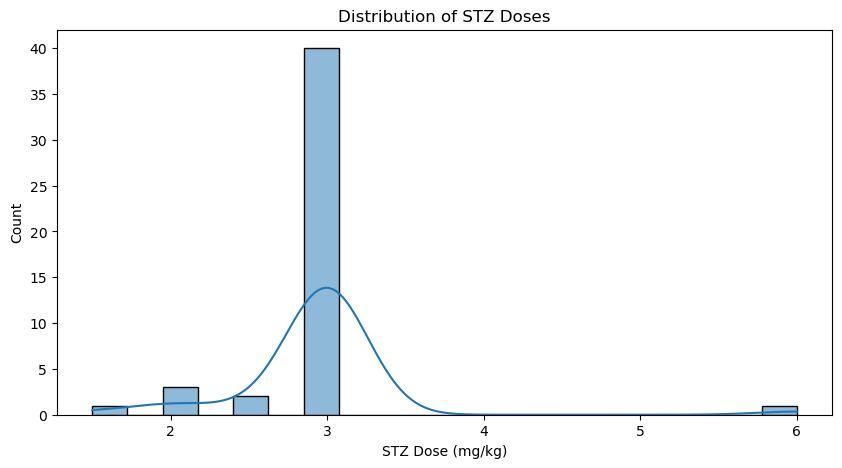

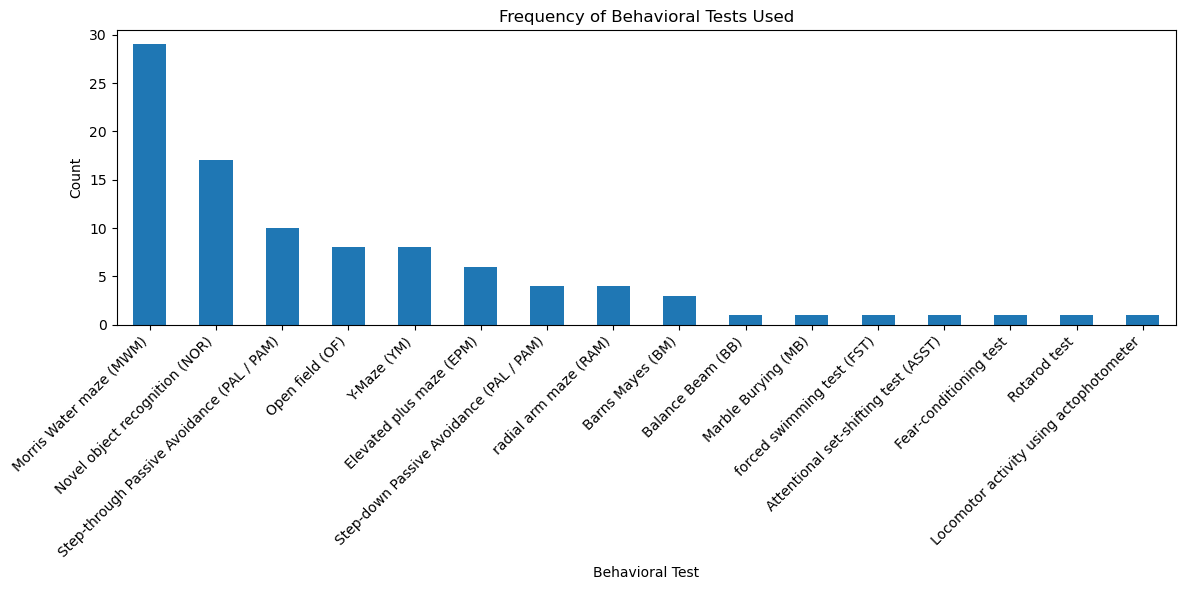

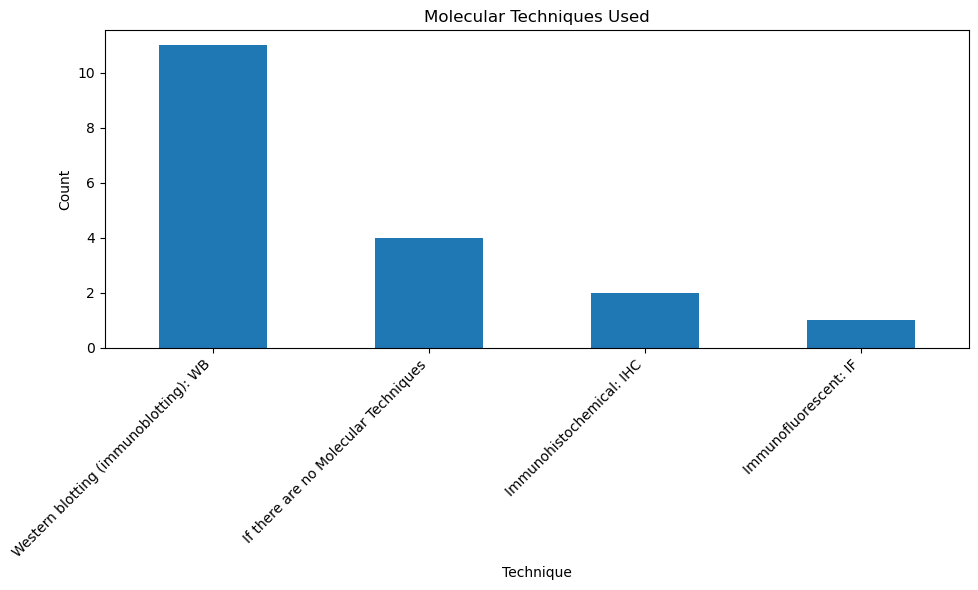

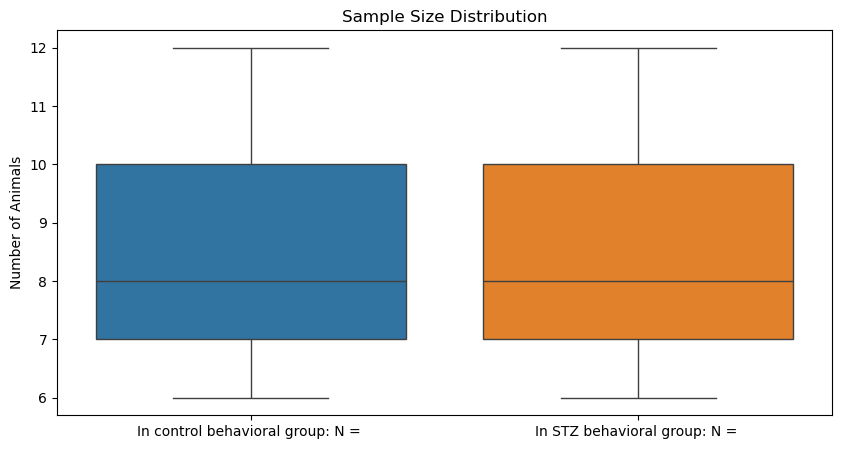

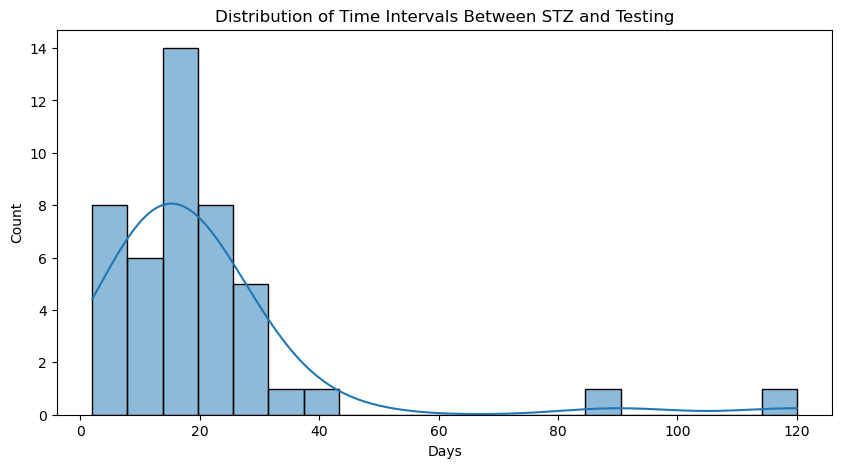

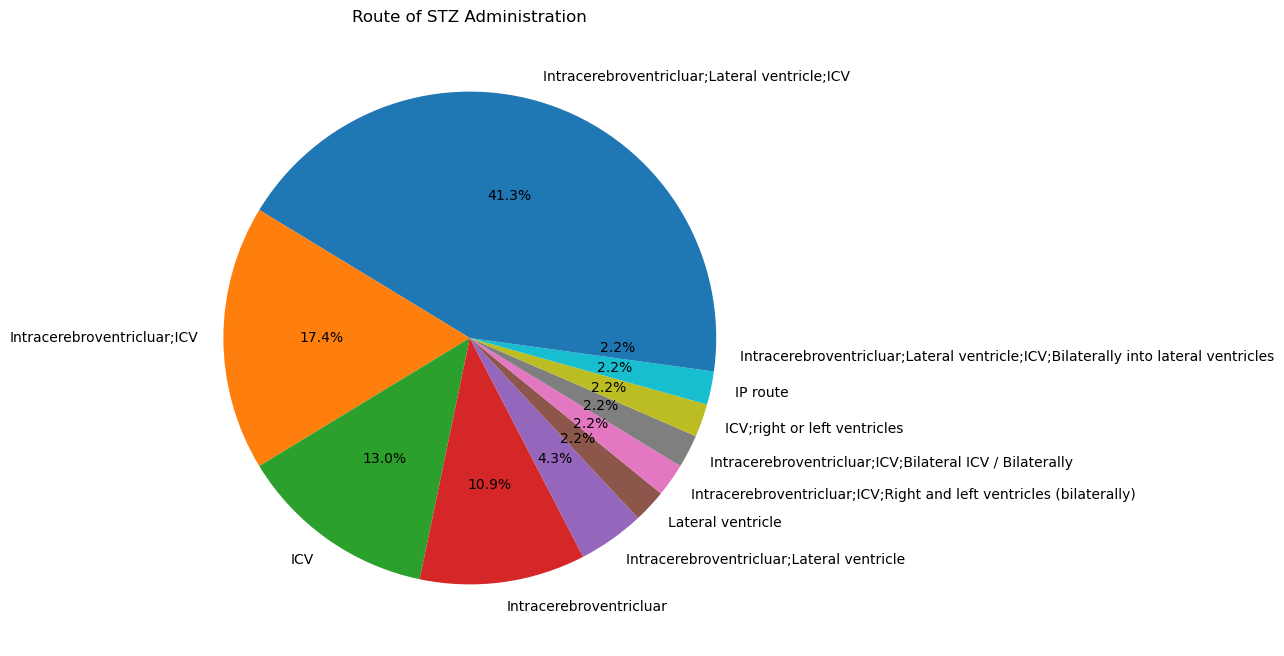

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

# Set up visualization style

## 1. Load and Prepare Data
df = pd.read_csv('STZ.csv')

# Display basic info
print(f"Dataset contains {len(df)} records")
print("\nFirst few records:")
display(df.head())

# Check for missing values
print("\nMissing values per column:")
display(df.isna().sum())

## 2. Basic Descriptive Statistics
# Papers per year
df['Year'] = df['Timestamp'].str.extract(r'(\d{4})')
year_counts = df['Year'].value_counts().sort_index()

plt.figure(figsize=(10,5))
year_counts.plot(kind='bar')
plt.title('Number of Papers per Year')
plt.xlabel('Year')
plt.ylabel('Count')
plt.show()

# Animal models used
animal_counts = df['Subject'].value_counts()
plt.figure(figsize=(6,6))
animal_counts.plot(kind='pie', autopct='%1.1f%%')
plt.title('Animal Models Used')
plt.ylabel('')
plt.show()

# STZ doses
stz_doses = df['STZ dose (mg/kg/rat)'].str.split(';').explode().str.strip()
stz_doses = pd.to_numeric(stz_doses, errors='coerce').dropna()

plt.figure(figsize=(10,5))
sns.histplot(stz_doses, bins=20, kde=True)
plt.title('Distribution of STZ Doses')
plt.xlabel('STZ Dose (mg/kg)')
plt.ylabel('Count')
plt.show()

## 3. Behavioral Tests Analysis
# Extract and count behavioral tests
behavior_col = 'Behavioral/Behavioural Type and Method (Test, task, maze)'
behavior_tests = df[behavior_col].str.split(';').explode().str.strip()
behavior_counts = behavior_tests.value_counts()

plt.figure(figsize=(12,6))
behavior_counts.plot(kind='bar')
plt.title('Frequency of Behavioral Tests Used')
plt.xlabel('Behavioral Test')
plt.ylabel('Count')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

## 4. Molecular Techniques Analysis
# Count molecular techniques
mol_tech_cols = [col for col in df.columns if 'Molecular Techniques' in col]
mol_tech = df[mol_tech_cols[0]].str.split(';').explode().str.strip()
mol_tech_counts = mol_tech.value_counts()

plt.figure(figsize=(10,6))
mol_tech_counts.plot(kind='bar')
plt.title('Molecular Techniques Used')
plt.xlabel('Technique')
plt.ylabel('Count')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

## 5. Sample Size Analysis
# Control vs STZ group sizes
df['In control behavioral group: N = '] = pd.to_numeric(df['In control behavioral group: N = '], errors='coerce')
df['In STZ behavioral group: N = '] = pd.to_numeric(df['In STZ behavioral group: N = '], errors='coerce')

plt.figure(figsize=(10,5))
sns.boxplot(data=df[['In control behavioral group: N = ', 'In STZ behavioral group: N = ']])
plt.title('Sample Size Distribution')
plt.ylabel('Number of Animals')
plt.show()

## 6. Time Interval Analysis
# Clean and convert time intervals
time_intervals = df['Interval between STZ administration and tests'].str.extract(r'(\d+)')[0]
time_intervals = pd.to_numeric(time_intervals, errors='coerce').dropna()

plt.figure(figsize=(10,5))
sns.histplot(time_intervals, bins=20, kde=True)
plt.title('Distribution of Time Intervals Between STZ and Testing')
plt.xlabel('Days')
plt.ylabel('Count')
plt.show()

## 7. Route of Administration Analysis
route_counts = df['Route of administration of STZ'].value_counts()

plt.figure(figsize=(8,8))
route_counts.plot(kind='pie', autopct='%1.1f%%')
plt.title('Route of STZ Administration')
plt.ylabel('')
plt.show()

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.weightstats import DescrStatsW

# Effect Size Calculation Functions
def hedges_g(mean1, mean2, sd1, sd2, n1, n2):
    """
    Calculate Hedges' g (biased-corrected standardized mean difference)
    """
    pooled_sd = np.sqrt(((n1 - 1) * sd1**2 + (n2 - 1) * sd2**2) / (n1 + n2 - 2))
    smd = (mean1 - mean2) / pooled_sd
    
    # Small-sample bias correction (J)
    df = n1 + n2 - 2
    J = 1 - (3 / (4 * df - 1))
    g = smd * J
    
    # Calculate variance
    var_g = ((n1 + n2) / (n1 * n2)) + (g**2 / (2 * (n1 + n2)))
    se_g = np.sqrt(var_g)
    
    return g, se_g

def extract_numeric(value):
    """Helper function to extract numeric values from strings"""
    if pd.isna(value):
        return np.nan
    try:
        # Handle ranges (e.g., "200-250")
        if '-' in str(value):
            parts = [float(x) for x in str(value).split('-')]
            return np.mean(parts)
        # Handle comma decimals (if any)
        return float(str(value).replace(',', '.'))
    except:
        return np.nan

# Prepare the data
def prepare_effect_size_data(df):
    """
    Prepare data for effect size calculations from the dataframe
    """
    results = []
    
    # Process behavioral data
    for idx, row in df.iterrows():
        if pd.notna(row['Behavioral/Behavioural Type and Method (Test, task, maze)']):
            n_control = extract_numeric(row['In control behavioral group: N = '])
            n_stz = extract_numeric(row['In STZ behavioral group: N = '])
            
            # Skip if missing sample sizes
            if pd.isna(n_control) or pd.isna(n_stz):
                continue
                
            # Add to results (we'll need to extract actual means/SDs from your plots/tables)
            results.append({
                'study_id': idx,
                'study_title': row['Title Paper'],
                'authors': row['Authors (First author {Last Name} et al., Year)'],
                'year': row['Timestamp'][:4],
                'outcome_type': 'behavioral',
                'test_name': row['Behavioral/Behavioural Type and Method (Test, task, maze)'],
                'n_control': n_control,
                'n_stz': n_stz,
                # These would come from your extracted plot/table data
                'mean_control': np.nan,  
                'mean_stz': np.nan,
                'sd_control': np.nan,
                'sd_stz': np.nan,
                'notes': 'Need to extract means/SDs from plots/tables'
            })
    
    # Process molecular data - example for Western blotting
    for idx, row in df.iterrows():
        if pd.notna(row['Molecular Techniques']):
            n_control = extract_numeric(row['In control molecular group: N = '])
            n_stz = extract_numeric(row['In STZ molecular group: N = '])
            
            if pd.isna(n_control) or pd.isna(n_stz):
                continue
                
            results.append({
                'study_id': idx,
                'study_title': row['Title Paper'],
                'authors': row['Authors (First author {Last Name} et al., Year)'],
                'year': row['Timestamp'][:4],
                'outcome_type': 'molecular',
                'test_name': row['Molecular Techniques'],
                'n_control': n_control,
                'n_stz': n_stz,
                'mean_control': np.nan,
                'mean_stz': np.nan,
                'sd_control': np.nan,
                'sd_stz': np.nan,
                'notes': 'Need to extract protein levels from Western blot data'
            })
    
    return pd.DataFrame(results)

# Create effect size dataframe
df = pd.read_csv('STZ.csv')
effect_df = prepare_effect_size_data(df)

# Example calculation (using placeholder values)
example_row = effect_df.iloc[0].copy()
example_row['mean_control'] = 10  # Example value from plot extraction
example_row['mean_stz'] = 15      # Example value from plot extraction
example_row['sd_control'] = 2     # Example value from plot extraction
example_row['sd_stz'] = 3         # Example value from plot extraction

g, se_g = hedges_g(
    example_row['mean_control'], 
    example_row['mean_stz'],
    example_row['sd_control'],
    example_row['sd_stz'],
    example_row['n_control'],
    example_row['n_stz']
)

print(f"Example Hedges' g calculation:")
print(f"Study: {example_row['study_title']}")
print(f"Test: {example_row['test_name']}")
print(f"Hedges' g = {g:.3f} (SE = {se_g:.3f})")
print(f"95% CI = [{g - 1.96*se_g:.3f}, {g + 1.96*se_g:.3f}]")

# Visualization of effect sizes (placeholder - would use real data)
plt.figure(figsize=(10, 6))
plt.errorbar(x=range(len(effect_df)), 
             y=[g]*len(effect_df), 
             yerr=[se_g*1.96]*len(effect_df),
             fmt='o',
             capsize=5)
plt.axhline(0, color='red', linestyle='--')
plt.title("Effect Sizes Across Studies (Example)")
plt.xlabel("Study Index")
plt.ylabel("Hedges' g (95% CI)")
plt.tight_layout()
plt.show()

KeyError: 'In control molecular group: N = '